# Member 2: Analysis & Visualization
**Project:** Credit Risk Scoring and Loan Default Analysis

This notebook creates the final EDA figures, with a caption and a short observation for each.

**Before you run it:**
1. Put `final_validated_dataset.csv` in the same folder as this notebook (in Colab: drag it into the Files panel on the left).
2. If the file has another name or folder, change `DATA_PATH` in the first code cell.
3. Run all cells from top to bottom (Runtime > Run all).

In this dataset, `loan_status` = 1 means **default** and 0 means **repaid**. Confirm this with Member 1.

In [1]:
# Step 1: libraries, colours, settings and data loading
import os
import numpy as np
import pandas as pd
import matplotlib

try:                      # True when running inside Jupyter / Colab
    get_ipython()
    SHOW = True
except NameError:         # False when running as a normal .py script
    SHOW = False
if not SHOW:
    matplotlib.use("Agg")  # save files only, do not open windows
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------- settings -----------------------------
DATA_PATH = "final_validated_dataset.csv"   # <- change this if your file is somewhere else
try:
    HERE = os.path.dirname(os.path.abspath(__file__))
except NameError:         # notebooks have no __file__
    HERE = os.getcwd()
OUT_DIR = os.path.join(HERE, "figures")
os.makedirs(OUT_DIR, exist_ok=True)

BLUE = "#2a78d6"     # paid / neutral
ORANGE = "#eb6834"   # default
INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.titlelocation": "left",
})

df = pd.read_csv(DATA_PATH)
df["is_default"] = df["loan_status"].astype(int)       # 1 = default, 0 = repaid
OVERALL = df["is_default"].mean() * 100
print("Rows:", len(df), "| overall default rate: %.1f%%" % OVERALL)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, name), bbox_inches="tight", facecolor="white")
    if SHOW:
        plt.show()
    plt.close(fig)
    print("saved", name)


def rate_table(col, order=None):
    g = df.groupby(col, observed=True)["is_default"].agg(["mean", "count"])
    g["rate"] = g["mean"] * 100
    if order is not None:
        g = g.reindex(order)
    return g[["rate", "count"]]


def rate_bars(ax, tbl, title, xlabel, color=ORANGE, rotate=0):
    x = np.arange(len(tbl))
    ax.bar(x, tbl["rate"], color=color, width=0.62)
    ax.axhline(OVERALL, color=MUTED, lw=1, ls="--", label="overall %.1f%%" % OVERALL)
    ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=8.5,
              handlelength=1.6, borderaxespad=0.2)
    for i, (r, n) in enumerate(zip(tbl["rate"], tbl["count"])):
        ax.text(i, r + 0.8, "%.1f%%" % r, ha="center", va="bottom", fontsize=9, color=INK,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.6, alpha=0.85))
        ax.text(i, 0.8, "n=%s" % format(int(n), ","), ha="center", va="bottom",
                fontsize=7.5, color="white" if r > 6 else MUTED)
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in tbl.index], rotation=rotate,
                       ha="right" if rotate else "center")
    ax.set_ylim(0, max(tbl["rate"].max() * 1.18, OVERALL * 1.3))
    ax.set_ylabel("Default rate (%)")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)

Rows: 32416 | overall default rate: 21.9%


**Helper functions.** `rate_table` calculates the default rate and loan count for each group. `rate_bars` draws the bar chart with the overall rate as a dashed line.

## Figure 1: Loan status

*Figure 1. Number and share of repaid and defaulted loans (n = 32,416).*

**Observation:** 7,089 of 32,416 loans (21.9%) defaulted, about 1 default for every 3.6 repaid loans. The target is imbalanced, so accuracy alone would be a misleading score for the model; recall, precision and ROC-AUC should also be reported.

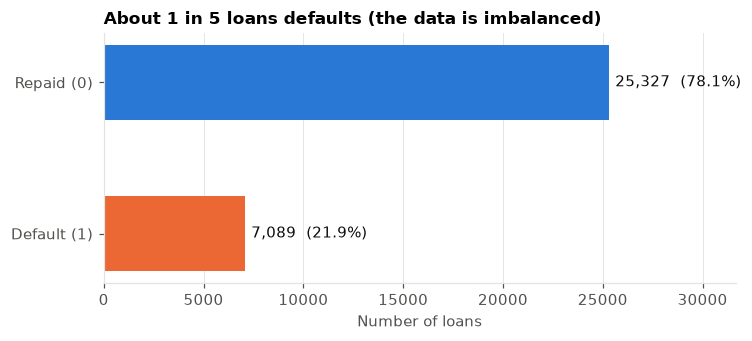

saved fig01_loan_status.png


In [2]:
# Figure 1: loan status distribution
counts = df["is_default"].value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(7, 3.2))
labels = ["Repaid (0)", "Default (1)"]
ax.barh(labels, counts.values, color=[BLUE, ORANGE], height=0.5)
for i, v in enumerate(counts.values):
    ax.text(v + 300, i, "%s  (%.1f%%)" % (format(v, ","), v / len(df) * 100), va="center", color=INK)
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Number of loans")
ax.set_title("About 1 in 5 loans defaults (the data is imbalanced)")
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
save(fig, "fig01_loan_status.png")

## Figure 2: Loan grade

*Figure 2. Default rate for each loan grade (A = best, G = worst). The dashed line is the overall default rate (21.9%); n is the number of loans in the group.*

**Observation:** Default rate rises from 10.0% (grade A) to 20.8% (grade C), then jumps to 59.1% at grade D and reaches 98.4% at grade G. Grades D-G hold 15.1% of loans (4,888) but default at 61.2%. Grade G has only 64 loans, so its rate is less reliable. Grade is assigned by the lender, so this pattern partly reflects the lender's own risk assessment.

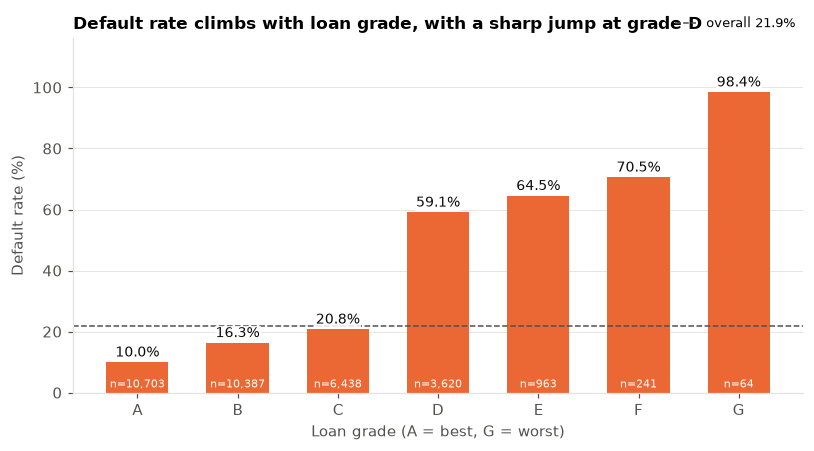

saved fig02_default_rate_by_grade.png


In [3]:
# Figure 2: default rate by grade
t_grade = rate_table("loan_grade", list("ABCDEFG"))
fig, ax = plt.subplots(figsize=(7.5, 4.2))
rate_bars(ax, t_grade, "Default rate climbs with loan grade, with a sharp jump at grade D", "Loan grade (A = best, G = worst)")
save(fig, "fig02_default_rate_by_grade.png")

## Figure 3: Loan size compared with income

*Figure 3. Default rate by loan amount as a share of annual income (loan_percent_income).*

**Observation:** Default rate is 11.8% when the loan is below 10% of income and 70.4% when it is above 30%. The 3,819 loans above 30% (11.8% of all loans) account for 37.9% of all defaults. This is one of the strongest patterns in the data.

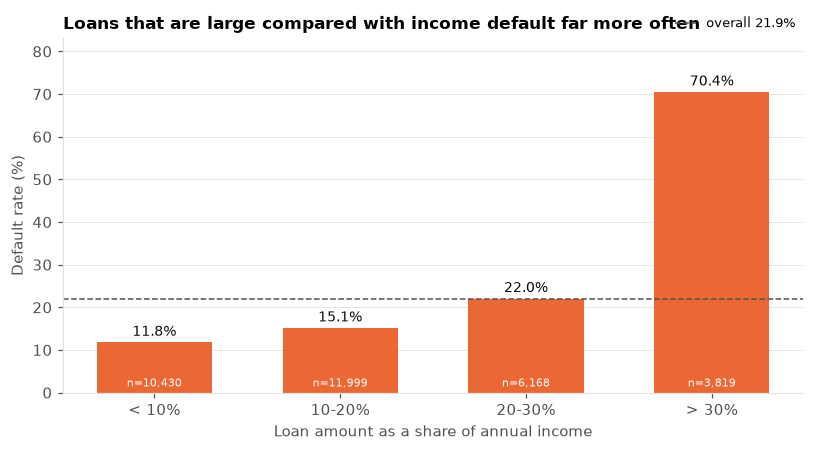

saved fig03_default_rate_by_loan_burden.png


In [4]:
# Figure 3: loan burden (loan as % of income)
df["burden_band"] = pd.cut(df["loan_percent_income"], [-0.001, 0.10, 0.20, 0.30, 1.0],
                           labels=["< 10%", "10-20%", "20-30%", "> 30%"])
t_burden = rate_table("burden_band")
fig, ax = plt.subplots(figsize=(7.5, 4.2))
rate_bars(ax, t_burden, "Loans that are large compared with income default far more often",
          "Loan amount as a share of annual income")
save(fig, "fig03_default_rate_by_loan_burden.png")

## Figure 4: Prior default and home ownership

*Figure 4. Default rate by prior default record (left) and home ownership (right).*

**Observation:** Applicants with a prior default on file default at 37.9% versus 18.4% for those without (about double). Renters default at 31.6% versus 12.6% for mortgage holders and 7.5% for owners; renters are 50.5% of loans but 73.0% of defaults. The OTHER group (n = 106) is too small for firm conclusions.

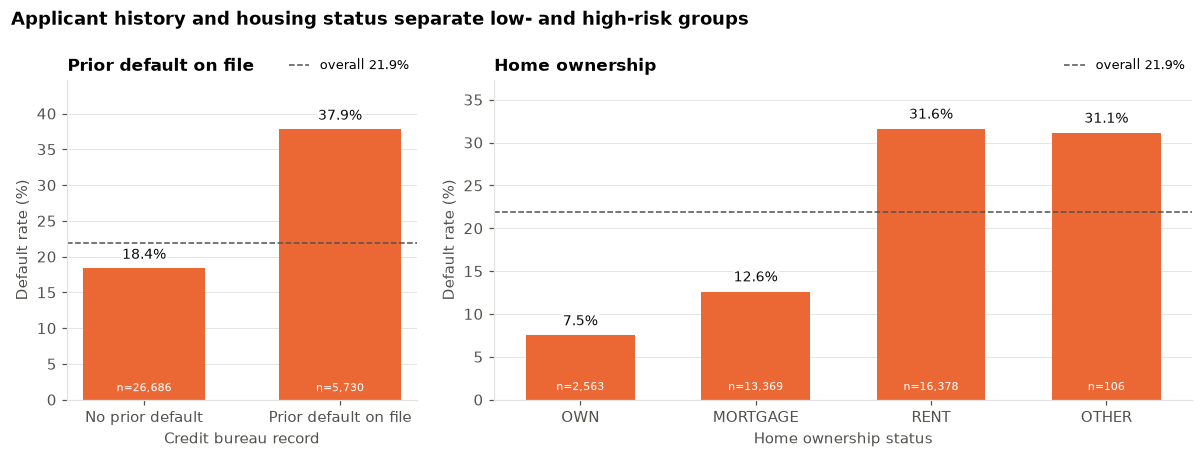

saved fig04_prior_default_and_home_ownership.png


In [5]:
# Figure 4: prior default + home ownership
t_prior = rate_table("cb_person_default_on_file", ["N", "Y"])
t_prior.index = ["No prior default", "Prior default on file"]
t_home = rate_table("person_home_ownership", ["OWN", "MORTGAGE", "RENT", "OTHER"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [2, 4]})
rate_bars(ax[0], t_prior, "Prior default on file", "Credit bureau record")
rate_bars(ax[1], t_home, "Home ownership", "Home ownership status")
fig.suptitle("Applicant history and housing status separate low- and high-risk groups",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
save(fig, "fig04_prior_default_and_home_ownership.png")

## Figure 5: Loan purpose

*Figure 5. Default rate by loan purpose, sorted from highest to lowest.*

**Observation:** Debt consolidation (28.7%), medical (26.8%) and home improvement (26.2%) loans default above the overall rate; venture (14.9%) and education (17.3%) loans default below it. The gap between purposes is up to 13.8 percentage points, smaller than the gaps for grade or loan burden.

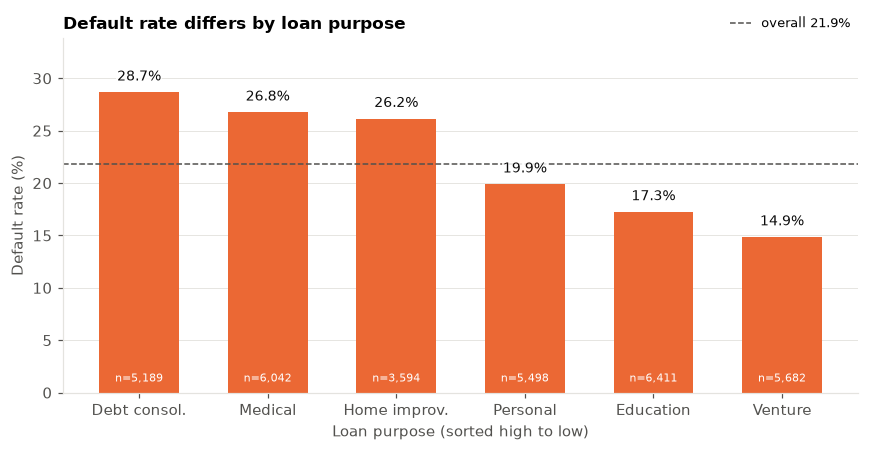

saved fig05_default_rate_by_loan_intent.png


In [6]:
# Figure 5: loan intent
t_intent = rate_table("loan_intent").sort_values("rate", ascending=False)
t_intent.index = [i.title().replace("Debtconsolidation", "Debt consol.").replace("Homeimprovement", "Home improv.")
                  for i in t_intent.index]
fig, ax = plt.subplots(figsize=(8, 4.2))
rate_bars(ax, t_intent, "Default rate differs by loan purpose", "Loan purpose (sorted high to low)")
save(fig, "fig05_default_rate_by_loan_intent.png")

## Figure 6: Applicant income

*Figure 6. Left: annual income of repaid and defaulted loans (log scale, extreme values hidden). Right: default rate by income quartile (k = thousand; currency not stated in the dataset).*

**Observation:** Median income is 41.7k for defaulted loans versus 60.0k for repaid loans. The lowest-income quartile (below 39k) defaults at 39.7%, the highest (above 79k) at 9.1%. Income is very skewed (maximum 6,000,000), so medians and quartiles are used instead of averages.

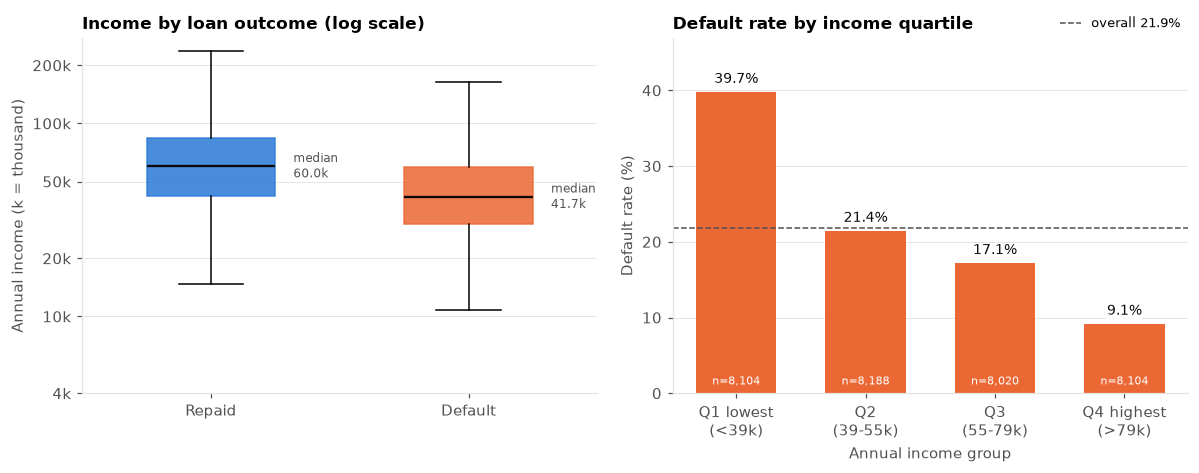

saved fig06_income.png


In [7]:
# Figure 6: income
df["income_q"] = pd.qcut(df["person_income"], 4)
q_edges = df["income_q"].cat.categories
q_labels = ["Q1 lowest\n(<%sk)" % int(round(q_edges[0].right / 1000)),
            "Q2\n(%s-%sk)" % (int(round(q_edges[1].left / 1000)), int(round(q_edges[1].right / 1000))),
            "Q3\n(%s-%sk)" % (int(round(q_edges[2].left / 1000)), int(round(q_edges[2].right / 1000))),
            "Q4 highest\n(>%sk)" % int(round(q_edges[3].left / 1000))]
t_inc = rate_table("income_q")
t_inc.index = q_labels
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
data = [np.log10(df.loc[df.is_default == 0, "person_income"]), np.log10(df.loc[df.is_default == 1, "person_income"])]
bp = ax[0].boxplot(data, patch_artist=True, widths=0.5, showfliers=False,
                   medianprops=dict(color=INK, lw=1.5))
for patch, c in zip(bp["boxes"], [BLUE, ORANGE]):
    patch.set_facecolor(c); patch.set_alpha(0.85); patch.set_edgecolor(c)
ax[0].set_xticks([1, 2]); ax[0].set_xticklabels(["Repaid", "Default"])
ticks = [4000, 10000, 20000, 50000, 100000, 200000]
ax[0].set_yticks(np.log10(ticks)); ax[0].set_yticklabels(["%sk" % int(t / 1000) for t in ticks])
ax[0].set_title("Income by loan outcome (log scale)")
ax[0].set_ylabel("Annual income (k = thousand)"); ax[0].grid(axis="x", visible=False)
med = df.groupby("is_default")["person_income"].median()
for i, k in enumerate([0, 1]):
    ax[0].text(i + 1.32, np.log10(med[k]), "median\n%.1fk" % (med[k] / 1000), fontsize=8, color=MUTED, va="center")
rate_bars(ax[1], t_inc, "Default rate by income quartile", "Annual income group")
save(fig, "fig06_income.png")

## Figure 7: Loan amount and interest rate

*Figure 7. Default rate by loan amount (left) and interest rate (right).*

**Observation:** Loans above 15k default at 32.4% versus 18.0% for 5k-10k, but the pattern is not smooth (20.5% for loans up to 5k). Interest rate shows a clearer pattern: 9.4% below 8% and 52.5% above 14%. Median interest rate is 13.48% for defaulted loans versus 10.65% for repaid loans. Like grade, the interest rate is set by the lender after assessing risk.

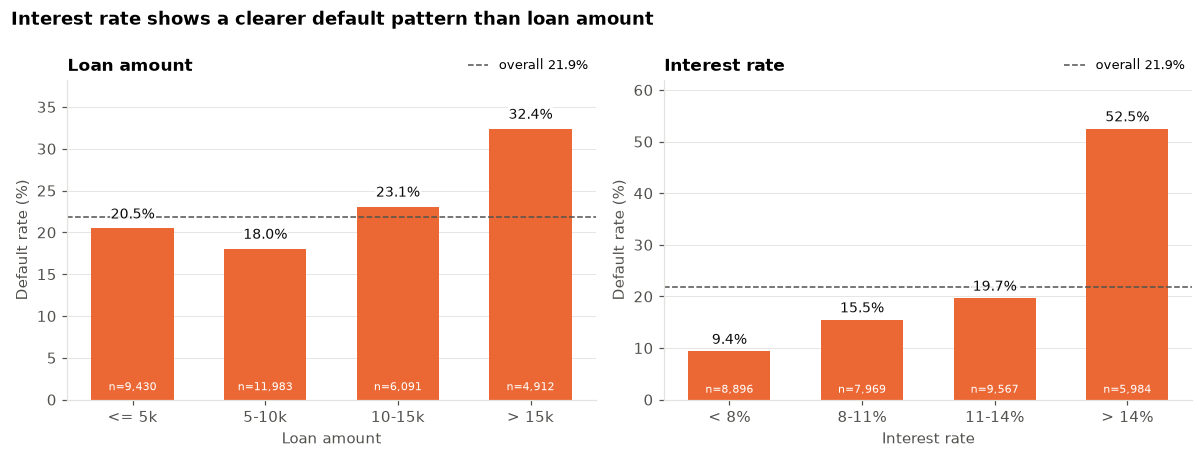

saved fig07_loan_amount_and_interest_rate.png


In [8]:
# Figure 7: loan amount + interest rate
df["amt_band"] = pd.cut(df["loan_amnt"], [0, 5000, 10000, 15000, 35000],
                        labels=["<= 5k", "5-10k", "10-15k", "> 15k"])
df["rate_band"] = pd.cut(df["loan_int_rate"], [0, 8, 11, 14, 30], labels=["< 8%", "8-11%", "11-14%", "> 14%"])
t_amt = rate_table("amt_band")
t_rate = rate_table("rate_band")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
rate_bars(ax[0], t_amt, "Loan amount", "Loan amount")
rate_bars(ax[1], t_rate, "Interest rate", "Interest rate")
fig.suptitle("Interest rate shows a clearer default pattern than loan amount",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
save(fig, "fig07_loan_amount_and_interest_rate.png")

## Figure 8: Age and employment length

*Figure 8. Default rate by age group (left) and years in current job (right).*

**Observation:** Age shows almost no pattern (20.2% to 23.3% across groups). Default rate falls as employment length increases: 27.9% for 0-1 years versus 16.4% for 10+ years.

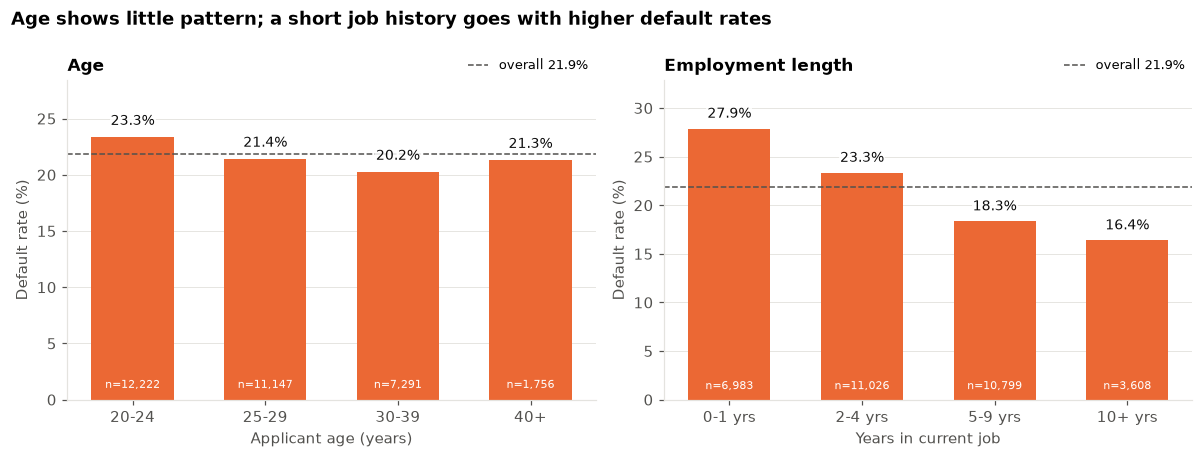

saved fig08_age_and_employment.png


In [9]:
# Figure 8: age + employment length
df["age_band"] = pd.cut(df["person_age"], [0, 24, 29, 39, 120], labels=["20-24", "25-29", "30-39", "40+"])
df["emp_band"] = pd.cut(df["person_emp_length"], [-1, 1, 4, 9, 100], labels=["0-1 yrs", "2-4 yrs", "5-9 yrs", "10+ yrs"])
t_age = rate_table("age_band")
t_emp = rate_table("emp_band")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
rate_bars(ax[0], t_age, "Age", "Applicant age (years)")
rate_bars(ax[1], t_emp, "Employment length", "Years in current job")
fig.suptitle("Age shows little pattern; a short job history goes with higher default rates",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
save(fig, "fig08_age_and_employment.png")

## Figure 9: Correlation heatmap

*Figure 9. Spearman correlation between numeric columns (orange = positive, blue = negative).*

**Observation:** The columns most associated with default are interest rate (0.32), loan share of income (0.32) and income (-0.27). Employment length (-0.10), loan amount (0.08), age (-0.03) and credit history length (-0.02) are weak. Age and credit history length are strongly correlated with each other (0.81), and loan amount with loan share of income (0.65), so some columns carry overlapping information. Correlation does not show that one factor causes default.

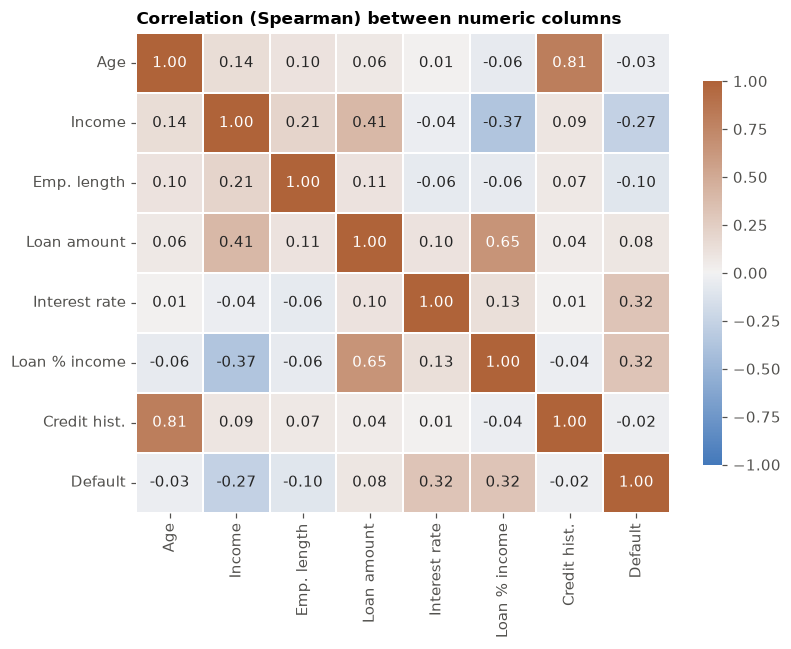

saved fig09_correlation_heatmap.png


In [10]:
# Figure 9: correlation heatmap
num = df[["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_int_rate",
          "loan_percent_income", "cb_person_cred_hist_length", "is_default"]].copy()
num.columns = ["Age", "Income", "Emp. length", "Loan amount", "Interest rate",
               "Loan % income", "Credit hist.", "Default"]
corr = num.corr(method="spearman")      # Spearman: robust to the income outliers
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(250, 30, as_cmap=True),
            center=0, vmin=-1, vmax=1, linewidths=1, linecolor="white", cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation (Spearman) between numeric columns")
ax.grid(False)
save(fig, "fig09_correlation_heatmap.png")

## Limitations

- Each chart compares one attribute at a time, but attributes overlap. Example: 21% of loans above 30% loan burden are grade D-G, versus 14% of other loans. Within grades D-G, a prior default adds almost nothing (60.8% without, 61.6% with).
- Two factors together can separate risk more than one alone. Example: low income (bottom quartile) with loan burden above 30% defaults at 77.8%; low income with burden of 30% or less at 27.8%; neither at 12.0%. The modelling team should test combinations, not single columns.
- These are patterns in historical data. They show association, not cause: for example, the data cannot show that renting causes default.
- Grade and interest rate are set by the lender, so their link with default partly shows the lender's own risk assessment.

## Data notes

- Assumption to confirm with Member 1: loan_status = 1 means default and 0 means repaid. The currency of income and loan amount is not stated, so figures show plain numbers.
- The file has 32,416 rows and 12 columns, with no missing values and no duplicate rows.
- A few extreme values remain: 2 applicants older than 80 (maximum 94), 1 applicant with 41 years of employment, and 9 incomes above 1,000,000 (maximum 6,000,000). They were kept; charts use log scale, medians and quartiles so they do not distort the results. Whether to remove them is a decision for the team.

## Numbers used in the observations
Run this cell to print the tables behind every observation (useful when someone asks 'where does this number come from?').

In [11]:
# numbers for the written observations ----------------
pd.set_option("display.width", 160)
print("\n--- default rate tables (rate %, n) ---")
for name, t in [("grade", t_grade), ("loan % income", t_burden), ("prior default", t_prior), ("home", t_home),
                ("intent", t_intent), ("income quartile", t_inc), ("loan amount", t_amt),
                ("interest rate", t_rate), ("age", t_age), ("emp length", t_emp)]:
    print("\n", name); print(t.round(1).to_string())
print("\nmedian income by outcome:\n", med)
print("\nmedian loan_percent_income by outcome:\n", df.groupby("is_default")["loan_percent_income"].median())
print("\nmedian interest rate by outcome:\n", df.groupby("is_default")["loan_int_rate"].median())
print("\nSpearman with default:\n", corr["Default"].drop("Default").sort_values(key=abs, ascending=False).round(2))
print("\nData-quality flags: age>80:", int((df.person_age > 80).sum()),
      "| emp_length>40:", int((df.person_emp_length > 40).sum()),
      "| income>1,000,000:", int((df.person_income > 1_000_000).sum()),
      "| emp_length > age-14:", int((df.person_emp_length > df.person_age - 14).sum()))
print("duplicate rows:", int(df.drop(columns=[c for c in df.columns if c.endswith(('_band', '_q'))]).duplicated().sum()))


--- default rate tables (rate %, n) ---

 grade
            rate  count
loan_grade             
A           10.0  10703
B           16.3  10387
C           20.8   6438
D           59.1   3620
E           64.5    963
F           70.5    241
G           98.4     64

 loan % income
             rate  count
burden_band             
< 10%        11.8  10430
10-20%       15.1  11999
20-30%       22.0   6168
> 30%        70.4   3819

 prior default
                       rate  count
No prior default       18.4  26686
Prior default on file  37.9   5730

 home
                       rate  count
person_home_ownership             
OWN                     7.5   2563
MORTGAGE               12.6  13369
RENT                   31.6  16378
OTHER                  31.1    106

 intent
              rate  count
Debt consol.  28.7   5189
Medical       26.8   6042
Home improv.  26.2   3594
Personal      19.9   5498
Education     17.3   6411
Venture       14.9   5682

 income quartile
                    ra